#

---
# Podsumowanie: lista kontrolna do zadania z pingwinami

1. Wczytaj dane, sprawdź `shape`, `info()`, wybierz etykietę.
2. EDA: rozkład klas, braki, skale, zależności (tabela, wykres). Zapisz wnioski i decyzje.
3. Usuń to, co zbędne (wiersze/kolumny) i **uzasadnij**.
4. Podział train/test **przed** przygotowaniem danych (`stratify`, `random_state`).
5. `ColumnTransformer`: liczby → imputer + scaler, kategorie → imputer + one-hot.
6. `make_pipeline(przygotowanie, model)`, `fit` na train.
7. Ewaluacja na test: `score`, baseline (`DummyClassifier`), macierz pomyłek, `classification_report`.
8. Iteracja: zmień jedną rzecz i porównaj.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# 1 - Wczytaj dane, sprawdź `shape`, `info()`, wybierz etykietę.

In [2]:
df = sns.load_dataset("penguins")
print(df.shape)
df.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


Etykieta: `species`, która ma trzy rózne wartości. To **klasyfikacja wieloklasowa**.

# 2 - EDA: rozkład klas, braki, skale, zależności (tabela, wykres). Zapisz wnioski i decyzje.

In [4]:
# rozkład etykiety
print(df["species"].value_counts(normalize=True).round(3))

# braki w procentach (tylko kolumny z brakami)
missing = df.isna().mean().mul(100).round(1)
missing[missing > 0]
print(missing)

missing_sum = df.isna().sum()
print(missing_sum)

missing_rows = df.isna().any(axis=1).sum()
print(missing_rows)

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64
species              0.0
island               0.0
bill_length_mm       0.6
bill_depth_mm        0.6
flipper_length_mm    0.6
body_mass_g          0.6
sex                  3.2
dtype: float64
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
11


In [5]:
# skale i skośność cech liczbowych
num_cols = ["bill_length_mm", 	"bill_depth_mm", 	"flipper_length_mm", 	"body_mass_g"]
print(df[num_cols].describe().round(1))
print("\nskośność:", df[num_cols].skew().round(2).to_dict())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%              44.4           17.3              197.0       4050.0
75%              48.5           18.7              213.0       4750.0
max              59.6           21.5              231.0       6300.0

skośność: {'bill_length_mm': 0.05, 'bill_depth_mm': -0.14, 'flipper_length_mm': 0.35, 'body_mass_g': 0.47}


In [6]:
df.groupby("species")[num_cols].mean().round(3)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.791,18.346,189.954,3700.662
Chinstrap,48.834,18.421,195.824,3733.088
Gentoo,47.505,14.982,217.187,5076.016


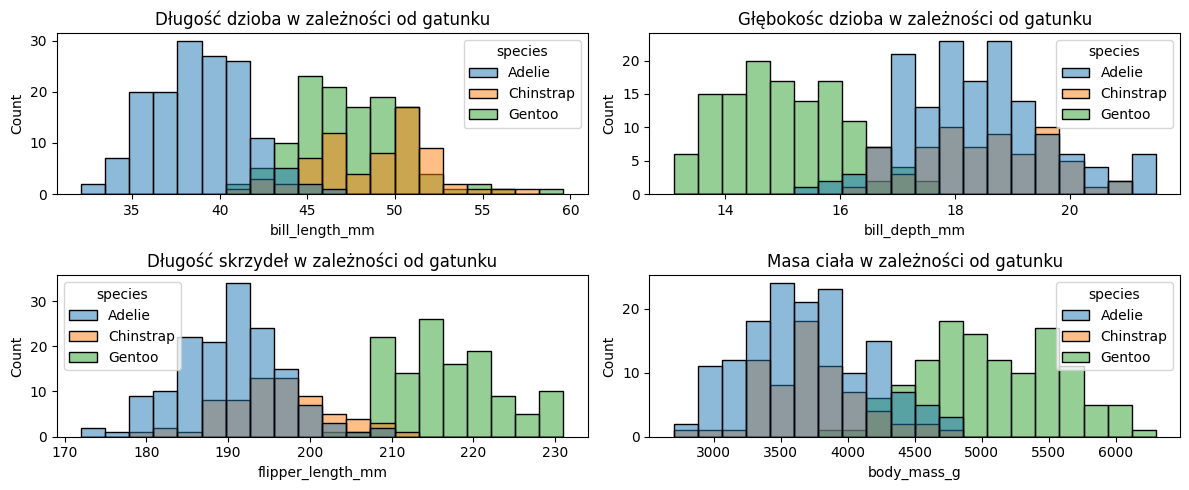

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 5))
sns.histplot(data=df, x="bill_length_mm", hue="species", bins=20, ax=axes[0, 0])
axes[0, 0].set_title("Długość dzioba w zależności od gatunku")
sns.histplot(data=df, x="bill_depth_mm", hue="species", bins=20, ax=axes[0, 1])
axes[0, 1].set_title("Głębokośc dzioba w zależności od gatunku")
sns.histplot(data=df, x="flipper_length_mm", hue="species", bins=20, ax=axes[1, 0])
axes[1, 0].set_title("Długość skrzydeł w zależności od gatunku")
sns.histplot(data=df, x="body_mass_g", hue="species", bins=20, ax=axes[1, 1])
axes[1, 1].set_title("Masa ciała w zależności od gatunku")
fig.tight_layout()
plt.show()

# 3 - Usuń to, co zbędne (wiersze/kolumny) i **uzasadnij**.

In [8]:
print(df['island'].value_counts())

print(df['sex'].value_counts())

print(df[num_cols].corr())

#Usuwamy 3% wierszy dla których brakuje danych, ponieważ stanowią one bardzo mały odsetek zbioru i ich usunięcie
#nie wpłynie negatywnie na reprezentatywność próby

df_without_na = df.dropna()

print(df_without_na.isna().sum())



island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
sex
Male      168
Female    165
Name: count, dtype: int64
                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm           1.000000      -0.235053           0.656181   
bill_depth_mm           -0.235053       1.000000          -0.583851   
flipper_length_mm        0.656181      -0.583851           1.000000   
body_mass_g              0.595110      -0.471916           0.871202   

                   body_mass_g  
bill_length_mm        0.595110  
bill_depth_mm        -0.471916  
flipper_length_mm     0.871202  
body_mass_g           1.000000  
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64


# 4 - Podział train/test **przed** przygotowaniem danych (`stratify`, `random_state`).

In [9]:
features = ["island", "sex", "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
target = "species"

X_train, X_test, y_train, y_test = train_test_split(
    df_without_na[features], df_without_na[target],
    test_size=0.25,        # 25% do testu
    stratify=df_without_na[target],   # ten sam odsetek ocalałych w obu częściach
    random_state=42,       # powtarzalny podział
)
print(X_train.shape, X_test.shape)
print(f"zbiór zawiera procentowo:\ntrain\n{y_train.value_counts(normalize=True)},\ntest\n{y_test.value_counts(normalize=True)}")

(249, 6) (84, 6)
zbiór zawiera procentowo:
train
species
Adelie       0.437751
Gentoo       0.357430
Chinstrap    0.204819
Name: proportion, dtype: float64,
test
species
Adelie       0.440476
Gentoo       0.357143
Chinstrap    0.202381
Name: proportion, dtype: float64


# 5 - `ColumnTransformer`: liczby → imputer + scaler, kategorie → imputer + one-hot.

In [10]:
przygotowanie = ColumnTransformer([
    ("liczby",    make_pipeline(StandardScaler()), num_cols),
    ("kategorie", make_pipeline(OneHotEncoder()), ['island', 'sex']),
])


# 6 - `make_pipeline(przygotowanie, model)`, `fit` na train.

In [11]:
model = make_pipeline(przygotowanie, LogisticRegression())
model

model.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('liczby',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler())]),
                                                  ['bill_length_mm',
                                                   'bill_depth_mm',
                                                   'flipper_length_mm',
                                                   'body_mass_g']),
                                                 ('kategorie',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder())]),
                                                  ['island', 'sex'])])),
                ('logisticregression', LogisticRegression())])

# 7 - Ewaluacja na test: `score`, baseline (`DummyClassifier`), macierz pomyłek, `classification_report`.

In [12]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

wyniki = pd.Series({
    "baseline (gatunek = Adelie)": baseline.score(X_test, y_test),
    "pipeline – train": model.score(X_train, y_train),
    "pipeline – test": model.score(X_test, y_test),
})
wyniki.round(3)

,0
baseline (gatunek = Adelie),0.440
pipeline – train,0.996
pipeline – test,0.988


# 8 - Iteracja: zmień jedną rzecz i porównaj.

In [17]:
przygotowanie_2 = ColumnTransformer([
    ("liczby",    make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder()), ['island']),
])

model_2 = make_pipeline(przygotowanie_2, LogisticRegression())
model_2

model_2.fit(X_train, y_train)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

wyniki = pd.Series({
    "pipeline – train": model_2.score(X_train, y_train),
    "pipeline – test": model_2.score(X_test, y_test),
})
wyniki.round(3)

,0
pipeline – train,0.996
pipeline – test,1.000


Porównując wyniki modelu 1 i 2(punkt 7 i 8) możemy stwierdzic, że brak kolumny płuci w modelu 2 spowodował dokładniejsze predykcje, co oznacza, że cecha ta nie jest konieczna do skutecznej oceny modelu, a nawet może ją osłabiać.